# Неделя 6 — Прототип sentiment-классификатора и PCA

Цель: применить векторы к тональности и сравнить с классическим baseline. Test не используется для выбора модели.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'nlp_project').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from nlp_project.core import corpus, clean, tokens, metrics, SEED
df = corpus()
train, val, test = [df[df.split == s].copy() for s in ('train', 'validation', 'test')]


BOW+NB / validation: {'accuracy': 0.8010204081632653, 'precision_macro': 0.8025641025641026, 'recall_macro': 0.8010204081632653, 'f1_macro': 0.8007662835249042, 'n': 196}


,model,split,accuracy,precision_macro,recall_macro,f1_macro,n
0,bow_nb,validation,0.801020,0.802564,0.801020,0.800766,196
1,bow_nb,test,0.802030,0.802778,0.802154,0.801949,197
2,tfidf_lr,validation,0.760204,0.760231,0.760204,0.760198,196
3,tfidf_lr,test,0.796954,0.797459,0.796846,0.796823,197
4,tfidf_nb,validation,0.790816,0.791089,0.790816,0.790767,196
5,tfidf_nb,test,0.807107,0.809092,0.807308,0.806863,197
6,word2vec_lr,validation,0.673469,0.676110,0.673469,0.672241,196
7,word2vec_lr,test,0.695431,0.695424,0.695424,0.695424,197
8,fasttext_lr,validation,0.622449,0.623270,0.622449,0.621819,196
9,fasttext_lr,test,0.634518,0.637964,0.634096,0.631776,197


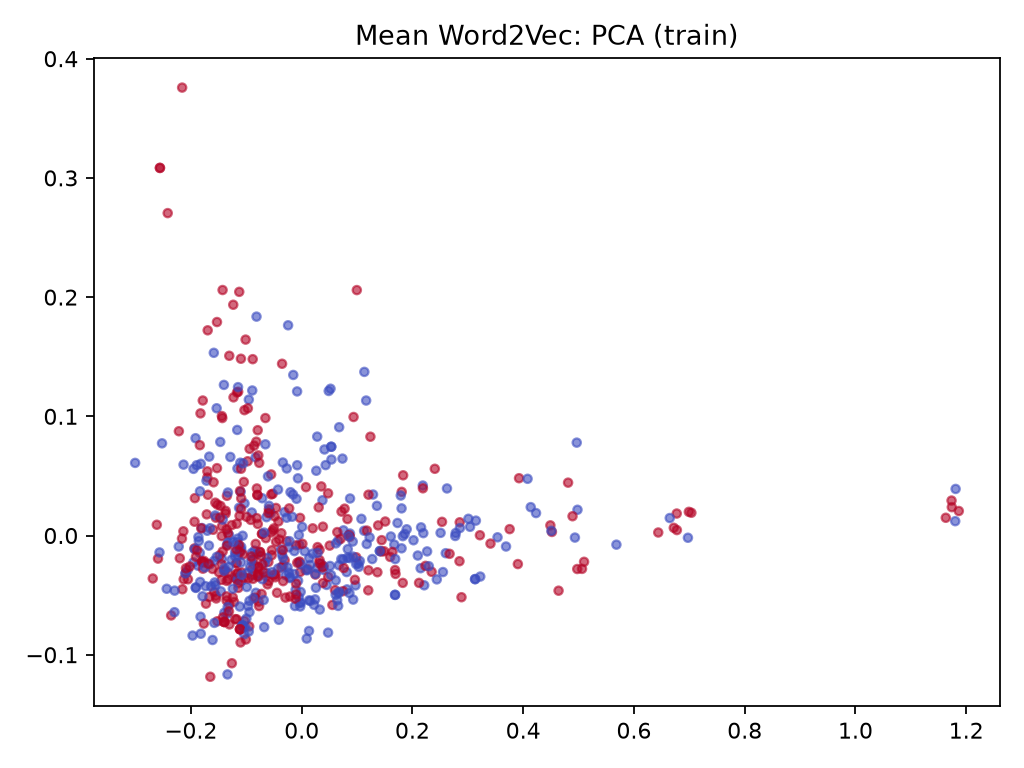

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from nlp_project.classical import vectorizer
model = Pipeline([('vec', vectorizer('bow')), ('clf', MultinomialNB())])
model.fit(train.text, train.label)
print('BOW+NB / validation:', metrics(val.label, model.predict(val.text)))
display(pd.read_csv(ROOT / 'reports/classical_metrics.csv'))
display(Image(filename=str(ROOT / 'reports/figures/embedding_pca.png')))


## Выводы

Готовый прототип работает на реальных отзывах. PCA отображает векторы в 2D, но не заменяет accuracy/F1. Лучший baseline выбирается по validation; полный test сохраняется для сравнения.